# Module 03: Matrices as Transformations

The most useful mental model in linear algebra: **a matrix is a function that moves space**. It sends every
vector somewhere new, keeping grid lines straight, evenly spaced, and the origin fixed. Once you see matrices this
way, matrix multiplication, inverses, determinants, eigenvectors and SVD all become pictures.

**Learning goals**
- Read a matrix by its columns: where e₁ and e₂ land
- Recognize rotation, scaling, shear, reflection and projection matrices
- Two views of matrix–vector multiplication: rows (dot products) and columns (combinations)
- Matrix multiplication as composition, and why AB ≠ BA
- Transpose, symmetric matrices, shape rules, batches (`X @ W`)
- A neural-network layer as a transformation

In [1]:
# Standard setup: make the repo root importable, load the usual tools, fix the random seed.
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parents[1]  # notebooks live in modules/XX_name/, so go up two levels
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from common.checks import check
from common import plotting as mplt

sp.init_printing()                         # pretty-print SymPy results as math
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)            # use rng.normal(...), rng.integers(...) for reproducible randomness

## 1. The columns tell you everything
Any vector is a combination of the basis vectors: $(x, y) = x\,\mathbf{e}_1 + y\,\mathbf{e}_2$. A linear
transformation T must keep combinations, so $T(x, y) = x\,T(\mathbf{e}_1) + y\,T(\mathbf{e}_2)$.
Knowing where $\mathbf{e}_1$ and $\mathbf{e}_2$ land tells you where *everything* lands. Write those two landing
spots as the **columns** of a matrix:
$$A = \begin{pmatrix} | & | \\ T(\mathbf{e}_1) & T(\mathbf{e}_2) \\ | & | \end{pmatrix}$$

In the plots below, the gray grid is the original space, the blue grid is the transformed space, and the red and
green arrows are the columns of A.

A e1 = [2. 0.] = first column [2. 0.]
A e2 = [1. 1.] = second column [1. 1.]


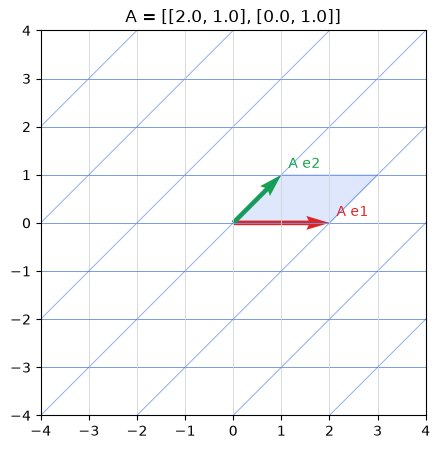

In [2]:
A = np.array([[2.0, 1.0],
              [0.0, 1.0]])
print("A e1 =", A @ np.array([1, 0]), "= first column", A[:, 0])
print("A e2 =", A @ np.array([0, 1]), "= second column", A[:, 1])
mplt.plot_linear_transform(A)
plt.show()

## 2. A gallery of transformations

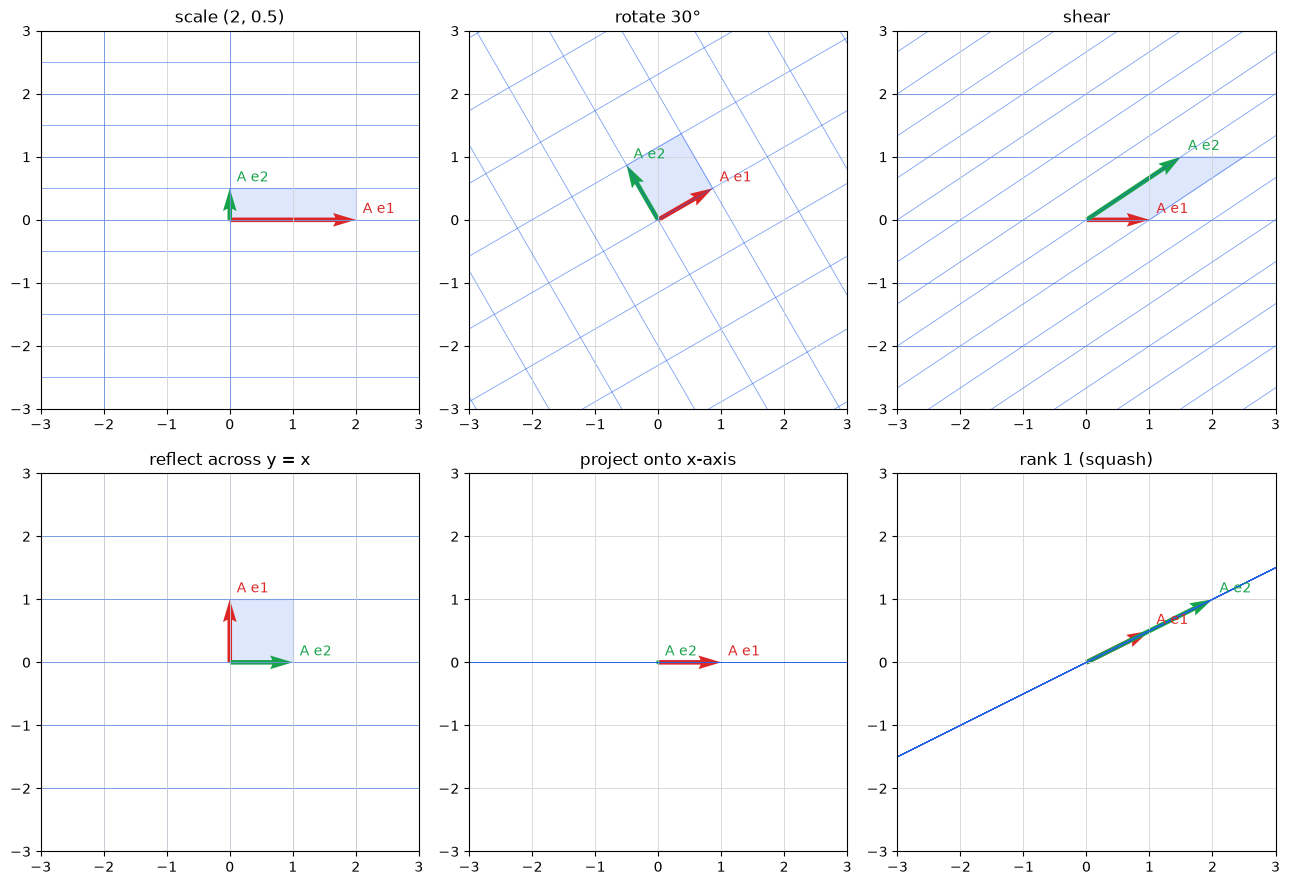

In [3]:
th = np.pi / 6
gallery = {
    "scale (2, 0.5)":       np.array([[2, 0], [0, 0.5]]),
    "rotate 30°":           np.array([[np.cos(th), -np.sin(th)], [np.sin(th), np.cos(th)]]),
    "shear":                np.array([[1, 1.5], [0, 1]]),
    "reflect across y = x": np.array([[0, 1], [1, 0]]),
    "project onto x-axis":  np.array([[1, 0], [0, 0]]),
    "rank 1 (squash)":      np.array([[1, 2], [0.5, 1]]),
}
fig, axs = plt.subplots(2, 3, figsize=(13, 9))
for ax, (name, M) in zip(axs.ravel(), gallery.items()):
    mplt.plot_linear_transform(M, ax=ax, lim=3, title=name)
plt.tight_layout()
plt.show()

Notice the last two: they squash the whole plane onto a **line**. Information is lost, and you can't undo them.
Module 04 calls these *singular* matrices.

## 3. Matrix–vector multiplication: two views
For $A \in \mathbb{R}^{m\times n}$ and $\mathbf{x} \in \mathbb{R}^n$:

**Row view:** each output entry is a dot product of a row of A with x: $(A\mathbf{x})_i = \sum_j A_{ij}x_j$.

**Column view:** the output is a linear combination of A's columns, weighted by x:
$A\mathbf{x} = x_1\mathbf{a}_1 + x_2\mathbf{a}_2 + \dots + x_n\mathbf{a}_n$.

Both give the same numbers. The row view is how you compute by hand. The column view is how you *think* ("the
output lives in the span of the columns").

In [4]:
A = np.array([[1.0, 2.0, 0.0],
              [3.0, -1.0, 4.0]])          # 2×3: maps R³ to R²
x = np.array([2.0, 1.0, -1.0])

row_view = np.array([A[0] @ x, A[1] @ x])
col_view = x[0] * A[:, 0] + x[1] * A[:, 1] + x[2] * A[:, 2]
print(row_view, col_view, A @ x)

[4. 1.] [4. 1.] [4. 1.]


## 4. Shapes: the rule that prevents most bugs
$(m \times n)$ times $(n \times p)$ gives $(m \times p)$. **The inner dimensions must match and disappear.**
A non-square $m \times n$ matrix maps $\mathbb{R}^n \to \mathbb{R}^m$: it changes dimension.

| expression | shapes | result |
|---|---|---|
| $A\mathbf{x}$ | (2×3)(3,) | (2,) |
| $AB$ | (2×3)(3×4) | (2×4) |
| $\mathbf{x}^\top\mathbf{y}$ | (1×n)(n×1) | scalar (inner product) |
| $\mathbf{x}\mathbf{y}^\top$ | (n×1)(1×m) | n×m matrix (**outer** product) |

In [5]:
B = rng.normal(size=(3, 4))
print((A @ B).shape)
try:
    B @ A
except ValueError as e:
    print("B @ A fails:", e)

xv, yv = np.array([1.0, 2.0, 3.0]), np.array([4.0, 5.0])
print("outer product:\n", np.outer(xv, yv))       # same as xv[:, None] * yv[None, :]

(2, 4)
B @ A fails: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 2 is different from 4)
outer product:
 [[ 4.  5.]
 [ 8. 10.]
 [12. 15.]]


## 5. Matrix multiplication = composition
$AB\mathbf{x} = A(B\mathbf{x})$: **first apply B, then A** (read right to left, like $f(g(x))$).
The columns of AB are A applied to each column of B. Order matters: rotating then shearing differs from shearing then
rotating.

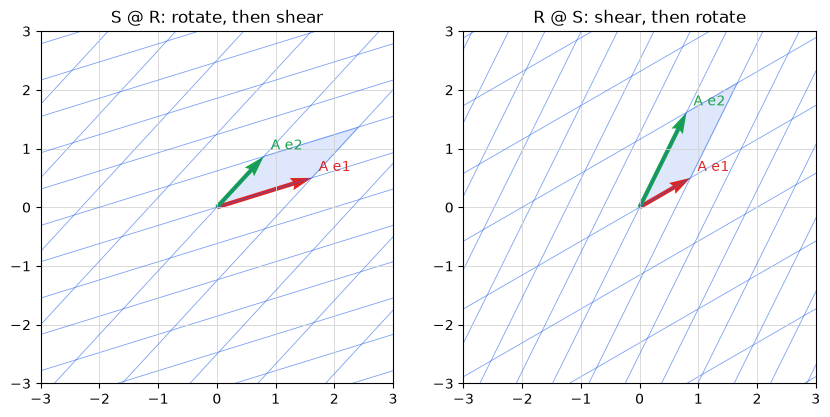

AB == BA? False


In [6]:
R = gallery["rotate 30°"]
S = gallery["shear"]
fig, axs = plt.subplots(1, 2, figsize=(10, 5))
mplt.plot_linear_transform(S @ R, ax=axs[0], lim=3, title="S @ R: rotate, then shear")
mplt.plot_linear_transform(R @ S, ax=axs[1], lim=3, title="R @ S: shear, then rotate")
plt.show()
print("AB == BA?", np.allclose(S @ R, R @ S))

Matrix multiplication is **associative**, $(AB)C = A(BC)$, but **not commutative**. Associativity is why a stack of
linear layers with no activation functions collapses into one matrix: $W_3W_2W_1\mathbf{x} = (W_3W_2W_1)\mathbf{x}$.
Nonlinear activations stop that collapse.

In [7]:
W1, W2, W3 = rng.normal(size=(5, 4)), rng.normal(size=(3, 5)), rng.normal(size=(2, 3))
xin = rng.normal(size=4)
print(np.allclose(W3 @ (W2 @ (W1 @ xin)), (W3 @ W2 @ W1) @ xin), (W3 @ W2 @ W1).shape)

True (2, 4)


## 6. Transpose and symmetric matrices
$A^\top$ swaps rows and columns: $(A^\top)_{ij} = A_{ji}$. Rules: $(A^\top)^\top = A$, $(AB)^\top = B^\top A^\top$
(the order flips!). A matrix is **symmetric** if $A = A^\top$. Covariance matrices and $X^\top X$ are always symmetric,
and module 06 shows they have especially nice eigenvectors.

In [8]:
X = rng.normal(size=(6, 3))
G = X.T @ X                       # the Gram matrix: 3×3 and symmetric
print(np.allclose(G, G.T), np.allclose((A @ B).T, B.T @ A.T))

True True


## 7. Batches: `X @ W` transforms every row at once
In ML the data matrix $X$ has shape (n_samples, n_features), one example per row. To transform every example with
the same matrix, use $XW$ (shape (n, d_in) @ (d_in, d_out) → (n, d_out)). Each row of the output is
$\mathbf{x}^{(i)\top} W$. This is why ML code writes `X @ W` rather than `W @ x`.

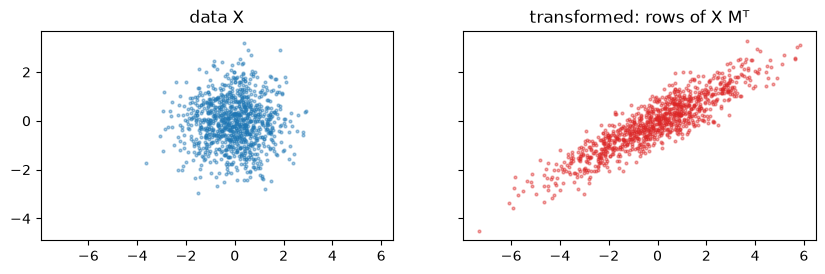

In [9]:
X = rng.normal(size=(1000, 2))
M = np.array([[2.0, 0.0], [1.0, 0.5]])
Y = X @ M.T                       # apply M to every row: (M x)ᵀ = xᵀ Mᵀ
fig, axs = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)
axs[0].scatter(*X.T, s=4, alpha=0.4); axs[0].set_title("data X")
axs[1].scatter(*Y.T, s=4, alpha=0.4, color=mplt.COLORS[1]); axs[1].set_title("transformed: rows of X Mᵀ")
for ax in axs: ax.set_aspect("equal")
plt.show()

## 8. A neural-network layer is a transformation (plus a bend)
A dense layer computes $\mathbf{h} = \text{ReLU}(W\mathbf{x} + \mathbf{b})$: a linear transformation, a shift, and then a
nonlinearity that *bends* space. Below, 2-D points on a grid pass through one layer with 2 hidden units. The matrix
shears and rotates the grid, the bias shifts it, and ReLU folds everything negative onto the axes.

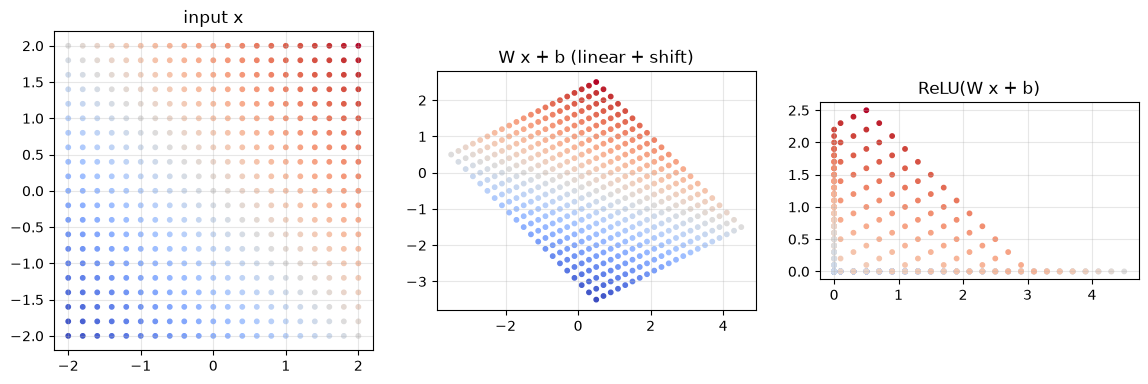

In [10]:
W = np.array([[1.0, -1.0], [0.5, 1.0]])
b = np.array([0.5, -0.5])
g = np.linspace(-2, 2, 21)
gx, gy = np.meshgrid(g, g)
pts = np.stack([gx.ravel(), gy.ravel()], axis=1)
lin = pts @ W.T + b
act = np.maximum(lin, 0)
fig, axs = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, P, title in zip(axs, [pts, lin, act], ["input x", "W x + b (linear + shift)", "ReLU(W x + b)"]):
    ax.scatter(P[:, 0], P[:, 1], c=pts[:, 0] + pts[:, 1], cmap="coolwarm", s=10)
    ax.set_title(title); ax.set_aspect("equal"); ax.grid(alpha=0.3)
plt.show()

## Where you'll use this
- **ML course:** 07 linear regression (`X @ w`), 10 pipelines (scaling is a diagonal matrix), 16 PCA (a rotation).
- **DL course:** 00 tensors (shapes), 01 MLP (`X @ W + b`), 07–08 convolutions (a structured matrix),
  14 attention (`Q @ K.T`).

## Summary
- The columns of A are the images of the basis vectors. That fixes the whole transformation.
- Ax is the rows dotted with x, or equally the columns combined with weights x.
- Shapes: (m×n)(n×p) → (m×p). A non-square matrix changes dimension.
- AB means "B first, then A". It is associative but not commutative, and (AB)ᵀ = BᵀAᵀ.
- With data in rows, transform a batch with X @ Wᵀ (or store W pre-transposed, as ML libraries do).

## 📚 Recommended videos, books and papers
⭐ = start here. The others are optional, for going deeper.

### 🎥 Videos
- ⭐ [Linear transformations and matrices (ch. 3)](https://www.3blue1brown.com/lessons/linear-transformations) (3Blue1Brown). The single most important video for this module.
- ⭐ [Matrix multiplication as composition (ch. 4)](https://www.3blue1brown.com/lessons/matrix-multiplication) (3Blue1Brown). Why matrix multiplication is defined the way it is.
- [Nonsquare matrices as transformations between dimensions (ch. 8)](https://www.3blue1brown.com/lessons/nonsquare-matrices) (3Blue1Brown). How a layer maps 784 dimensions down to 10.

### 📘 Books and articles
- [Deep Learning, ch. 2.1–2.3](https://www.deeplearningbook.org/contents/linear_algebra.html) (Goodfellow, Bengio & Courville, 2016). A compact summary of the notation for scalars, vectors, matrices and tensors.